# Ejercicio 3 · ¿Quién tiene diabetes?


**Módulo 5072 · SAA · UD3 · Métodos ensemble** · 
Un centro de salud quiere detectar pronto a las pacientes con diabetes. Tenemos 768 mujeres con sus análisis: glucosa, presión, índice de masa corporal, edad, número de embarazos... **El 35 % tiene diabetes.**

- **Qué predecimos:** `Outcome` (1 = tiene diabetes). Es **clasificación**.
- **Métricas:** tres a la vez. Elegimos con el **F1**, y miramos también el **recall** (cuántas pacientes con diabetes encuentra) y el **AUC**.

**Qué vas a hacer:** entrenar cinco modelos, compararlos en una tabla y elegir uno.

**Cómo trabajar:**
- Las celdas que dicen **«ya está hecha»**: solo ejecútalas y lee el resultado.
- Las celdas **«# Tu código»**: escribe tú el código. Si te atascas, abre la **Pista 1** (qué hay que hacer) y, si hace falta, la **Pista 2** (el código con huecos `___`).
- Al final miras **en qué variables se fija** el modelo.

## 1 · Preparación

Ejecuta las celdas una a una y mira qué sale. Algunas tienen huecos `___`: rellénalos (ya lo hiciste en los ejercicios anteriores).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

DATA = "../data/"
SEMILLA = 42

# 1. Cargar los datos
df = pd.read_csv(DATA + "diabetes.csv")
print(df.shape, "· con diabetes:", round(100 * df["Outcome"].mean(), 1), "%")

(768, 9) · con diabetes: 34.9 %


In [3]:
# 2. X (las pistas) e y (si tiene diabetes)
X = df.drop(columns="Outcome")
y = df["Outcome"]

In [4]:
# 3. Apartamos el 20 % para el test, con el mismo % de diabetes en train y en test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
print("Con diabetes · train:", round(y_train.mean(), 3), "· test:", round(y_test.mean(), 3))

Con diabetes · train: 0.349 · test: 0.351


In [5]:
# 4. No hay huecos ni columnas de texto

In [6]:
# 5. Validación cruzada: el train en 5 trozos
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

In [7]:
# 6. evaluar(): validación cruzada con TRES métricas a la vez.
#    Entrena el modelo 5 veces y mide en el trozo de validación de cada vez. El test no se toca.
def evaluar(nombre, modelo):
    r = cross_validate(modelo, X_train, y_train, cv=cv,
                       scoring=["f1", "recall", "roc_auc"], return_train_score=True)
    return {"modelo": nombre,
            "F1 val": r["test_f1"].mean(),
            "± F1 val": r["test_f1"].std(),
            "recall val": r["test_recall"].mean(),
            "AUC val": r["test_roc_auc"].mean(),
            "F1 train": r["train_f1"].mean()}

def mostrar(resultados):
    return pd.DataFrame(resultados).round(3)

In [8]:
# 7. Baseline: el modelo más tonto, que dice «sí» a todos.
#    Encuentra a todos los positivos (recall 1), pero no ordena nada (AUC 0,5).
p = y_train.mean()          # proporción de positivos
f1_base = 2 * p / (1 + p)   # el F1 de decir siempre que sí
resultados = [{"modelo": "Baseline (todos sí)", "F1 val": f1_base, "± F1 val": np.nan,
               "recall val": 1.0, "AUC val": 0.5, "F1 train": f1_base}]
print("Listo:", len(X_train), "pacientes para entrenar y validar ·", len(X_test), "para el test")

Listo: 614 pacientes para entrenar y validar · 154 para el test


**Qué han hecho estas celdas** (en los pasos 2, 3 y 5 has rellenado tú los huecos)
1. Carga las 768 pacientes.
2. Separa `X` (los análisis) e `y` (si tiene diabetes).
3. Aparta el 20 % para el **test**. `stratify=y` deja el mismo % de diabetes en train y en test: compruébalo en lo que imprime.
4. No hay huecos ni texto. Ojo: algunos ceros (presión 0, insulina 0) son en realidad datos que faltan. Los árboles lo aguantan bien y no los tocamos.
5. Prepara la **validación cruzada** de 5 trozos.
6. Crea `evaluar()`, ahora con **tres métricas**: le pasamos una lista en `scoring`.
7. Crea la tabla `resultados` con el **baseline**: decir «sí» a todas.

**Cómo leer la tabla** (tres métricas a la vez)
- `F1 val`: equilibrio entre encontrar a los pacientes con diabetes y no dar falsas alarmas (0 = fatal, 1 = perfecto). **Es la que usamos para comparar.**
- `± F1 val`: cuánto cambia el F1 de un trozo de validación a otro. Si dos modelos se diferencian menos que esto, es un **empate**.
- `recall val`: de cada 100 pacientes con diabetes, a cuántos encuentra (0,70 = 70 de cada 100).
- `AUC val`: si ordena bien de más a menos riesgo, sin fijar ningún umbral (0,5 = al azar, 1 = perfecto).
- `F1 train`: el F1 con los datos que ya ha visto. Si es mucho más alto que `F1 val`, el modelo **memoriza**.

In [9]:
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.517,NaN,1.0,0.5,0.517


**Fíjate:** ¿Qué recall tiene el baseline? ¿Y qué AUC? ¿Por qué decir «sí» a todas no sirve, aunque encuentre a todas las pacientes con diabetes?

*Tu respuesta:*

Recall 1.0 encuentra 100 de cada 100 diabéticas y AUC 0.5. Decir sí a todas no sirve porque da falsa alarma a todas las sanas, por eso F1 solo 0.517 y AUC 0.5 es azar, no ordena por riesgo.

## 2 · Tu turno: entrena y compara

**Tarea 1 · Un árbol sin límite.** Evalúalo y añádelo a `resultados`.

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

Llama a `evaluar()` con un nombre y el modelo `DecisionTreeClassifier` sin límite (sin `max_depth`). Añade la fila a `resultados` con `append` y muestra la tabla.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("Árbol sin límite", ___(random_state=SEMILLA)))
mostrar(resultados)
```

</details>

In [10]:
resultados.append(evaluar("Árbol sin límite", DecisionTreeClassifier(random_state=SEMILLA)))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.517,NaN,1.000,0.500,0.517
1,Árbol sin límite,0.534,0.019,0.523,0.645,1.000


**Fíjate:** Compara `F1 train` y `F1 val`. ¿Memoriza?

*Tu respuesta:*

Sí memoriza mucho. Train 1.0 vs val 0.534 hueco 0.466 se aprende de memoria el train

**Tarea 2 · Random Forest de 300 árboles.**

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

El modelo es `RandomForestClassifier` y el número de árboles va en `n_estimators`. `n_jobs=-1` usa todos los núcleos del ordenador: va más rápido.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("Random Forest", ___(n_estimators=___, random_state=SEMILLA, n_jobs=-1)))
mostrar(resultados)
```

</details>

In [11]:
# Tu código
resultados.append(evaluar("Random Forest", RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1)))
mostrar(resultados)


,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.517,NaN,1.000,0.500,0.517
1,Árbol sin límite,0.534,0.019,0.523,0.645,1.000
2,Random Forest,0.630,0.026,0.575,0.817,1.000


**Fíjate:** ¿Mejora al árbol? ¿La diferencia es mayor que el `±`?

*Tu respuesta:*

Sí mejora. De 0.534 a 0.630 dif 0.096 mayor que el ± 0.019 y 0.026 no es empate

**Tarea 3 · AdaBoost de 200 árboles.** Árboles de una sola pregunta en fila: cada uno se fija más en los casos que fallaron los anteriores.

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

El modelo es `AdaBoostClassifier` y el número de árboles va en `n_estimators`.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("AdaBoost", ___(n_estimators=___, random_state=SEMILLA)))
mostrar(resultados)
```

</details>

In [12]:
# Tu código
resultados.append(evaluar("AdaBoost", AdaBoostClassifier(n_estimators=200, random_state=SEMILLA)))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.517,NaN,1.000,0.500,0.517
1,Árbol sin límite,0.534,0.019,0.523,0.645,1.000
2,Random Forest,0.630,0.026,0.575,0.817,1.000
3,AdaBoost,0.645,0.034,0.598,0.808,0.740


**Fíjate:** ¿Mejora al árbol? ¿Memoriza?

*Tu respuesta:*

Ya no memoriza y si mejora al árbol ligeramente

**Tarea 4 · XGBoost por defecto.**

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

El modelo es `XGBClassifier`. Sin tocar nada: 100 árboles de hasta 6 preguntas y `learning_rate` 0,3.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("XGBoost por defecto", ___(random_state=SEMILLA)))
mostrar(resultados)
```

</details>

In [13]:
# Tu código
resultados.append(evaluar("XGBoost por defecto", XGBClassifier(random_state=SEMILLA)))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.517,NaN,1.000,0.500,0.517
1,Árbol sin límite,0.534,0.019,0.523,0.645,1.000
2,Random Forest,0.630,0.026,0.575,0.817,1.000
3,AdaBoost,0.645,0.034,0.598,0.808,0.740
4,XGBoost por defecto,0.603,0.018,0.575,0.773,1.000


**Fíjate:** Compara `F1 train` y `F1 val`. ¿Memoriza?

*Tu respuesta:*

Efectivamente vuelve a memorizar el train ha vuelto a subir a 1 y el hueco con val es grande.

**Tarea 5 · XGBoost con frenos.** Pon:
- `max_depth=3`: árboles pequeños.
- `learning_rate=0.05`: poco caso a cada árbol.
- `n_estimators=300`: como le hacemos poco caso a cada uno, hacen falta más árboles.

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

Guarda el modelo en la variable `xgb_frenos` (la usaremos en el test) y después pásalo a `evaluar()`.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
xgb_frenos = XGBClassifier(max_depth=___, learning_rate=___, n_estimators=___, random_state=SEMILLA)
resultados.append(evaluar("XGBoost con frenos", xgb_frenos))
mostrar(resultados)
```

</details>

In [14]:
# Tu código
xgb_frenos = XGBClassifier(max_depth=3, learning_rate=0.05, n_estimators=300, random_state=SEMILLA)
resultados.append(evaluar("XGBoost con frenos", xgb_frenos))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.517,NaN,1.000,0.500,0.517
1,Árbol sin límite,0.534,0.019,0.523,0.645,1.000
2,Random Forest,0.630,0.026,0.575,0.817,1.000
3,AdaBoost,0.645,0.034,0.598,0.808,0.740
4,XGBoost por defecto,0.603,0.018,0.575,0.773,1.000
5,XGBoost con frenos,0.625,0.033,0.594,0.794,0.917


**Fíjate:** Compáralo con el XGBoost por defecto. ¿Memoriza menos? ¿Mejora `F1 val`?

*Tu respuesta:*

Memoriza menos. Por defecto tiene 1 en train y hueco algo con frenos baja el train a 0.917

## 3 · ¿Cuál elegimos?

Esta celda ya está hecha: ejecútala. Ordena la tabla: el mejor queda arriba.

In [15]:
mostrar(pd.DataFrame(resultados).sort_values("F1 val", ascending=False))

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
3,AdaBoost,0.645,0.034,0.598,0.808,0.740
2,Random Forest,0.630,0.026,0.575,0.817,1.000
5,XGBoost con frenos,0.625,0.033,0.594,0.794,0.917
4,XGBoost por defecto,0.603,0.018,0.575,0.773,1.000
1,Árbol sin límite,0.534,0.019,0.523,0.645,1.000
0,Baseline (todos sí),0.517,NaN,1.000,0.500,0.517


Contesta:
1. ¿Qué modelo gana?
2. Resta su `F1 val` y el del segundo. ¿La diferencia es mayor que el `±`? ¿Gana o es un empate?
3. ¿Cuál eliges? Si hay empate, elige el más sencillo o el más rápido.

*Tu respuesta:*

 1. Gana AdaBoost 0.645
 2. Resta al segundo 0.645-0.630=0.015 menor que ± 0.034 y 0.026 es empate. Con XGBoost frenos 0.645-0.625=0.020 también < ± es todo empate arriba.
 3. Elijo AdaBoost porque en el empate es el que no memoriza train 0.740 vs val 0.645 hueco 0.09 y es el más sencillo/rápido de los 3 de arriba.

## 4 · ¿En qué se fija el modelo?

> **Para entenderlo · Importancia de las variables**
>
> Un Random Forest entrenado guarda en `feature_importances_` cuánto le ha servido cada variable para hacer sus preguntas. Cada número va de 0 a 1 y entre todas suman 1.
>
> - Una variable con importancia alta separa bien los casos.
> - **No dice hacia dónde**: no sabemos si subirla aumenta o baja la predicción.
> - **No dice que sea la causa**: solo que al modelo le sirve para acertar.

**4.1** Entrena un Random Forest de 300 árboles con todo el train y dibuja la importancia de cada variable. El gráfico ya está hecho: solo rellena los huecos.

<details><summary><b>Pista</b></summary>

Para entrenar: `.fit(X_train, y_train)`. La importancia está en `rf.feature_importances_`.

</details>

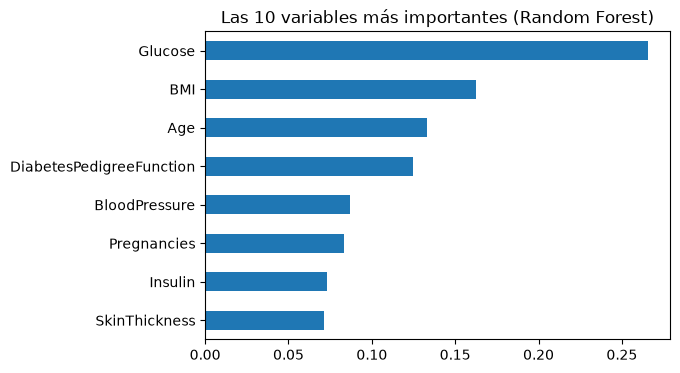

In [16]:
rf = RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1).fit(X_train, y_train)
importancia = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()

importancia.tail(10).plot.barh(figsize=(6, 4), title="Las 10 variables más importantes (Random Forest)")
plt.show()

**Cómo leer el gráfico:** cada barra es una variable. Cuanto más larga, más le sirve al modelo. La más importante queda arriba.

Contesta:
1. ¿Cuál es la variable más importante? ¿Tiene sentido?
2. ¿Cuáles son la segunda y la tercera?
3. ¿Dónde quedan los embarazos (`Pregnancies`) y la edad (`Age`)? Recuerda: importante no quiere decir que sea la causa.

*Tu respuesta:*

1. Glucose la más larga. Sí tiene sentido diabetes es glucosa alta.
2. Segunda BMI tercera Age
3. Pregnancies 6ª baja y Age 3ª arriba. No es causa es que a más embarazos/edad más riesgo correlación pero no causa directa.

## 5 · El test, una sola vez

Esta celda ya está hecha: ejecútala. Entrena el Random Forest y el XGBoost con frenos con todo el train y los prueba en el test, que hasta ahora no habíamos tocado.

In [17]:
from sklearn.metrics import f1_score, recall_score

rf = RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1).fit(X_train, y_train)
xgb_frenos.fit(X_train, y_train)

for nombre, modelo in [("Random Forest", rf), ("XGBoost con frenos", xgb_frenos)]:
    pred = modelo.predict(X_test)                  # 0 o 1
    prob = modelo.predict_proba(X_test)[:, 1]      # probabilidad de 1
    print(f"{nombre:18s} · F1 test {f1_score(y_test, pred):.3f} · recall {recall_score(y_test, pred):.3f} · AUC {roc_auc_score(y_test, prob):.3f}")

Random Forest      · F1 test 0.641 · recall 0.611 · AUC 0.812
XGBoost con frenos · F1 test 0.615 · recall 0.593 · AUC 0.834


**Fíjate:** ¿El resultado del test se parece al de validación (`F1 val`)? Si se parece, la validación nos dijo la verdad.

*Tu respuesta:*

Si se parece. RF val 0.630 ±0.026 test 0.641 dentro del ±. XGB frenos val 0.625 ±0.033 test 0.615 también dentro. La validación dijo la verdad no hay sorpresa.

## 6 · Conclusión

En dos o tres frases: ¿qué modelo eliges? ¿Por qué? Usa números de la tabla.

*Tu respuesta:*

Elijo Random Forest. F1 test 0.641 > XGB con frenos 0.615 y recall 0.611 > 0.593, es el mejor en la métrica pedida.

## 7 · Experimenta: tres pruebas más

Tres pruebas cortas. Van en una tabla aparte, `extra`, para no mezclarlas con la de antes.

**Extra 1 · ¿Cuántos árboles hacen falta?** Esta celda ya está hecha: ejecútala. Entrena Random Forest con 10, 50 y 100 árboles.

In [18]:
extra = []
for n in [10, 50, 100]:
    extra.append(evaluar(f"Random Forest de {n} árboles", RandomForestClassifier(n_estimators=n, random_state=SEMILLA, n_jobs=-1)))
mostrar(extra)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Random Forest de 10 árboles,0.575,0.038,0.505,0.781,0.970
1,Random Forest de 50 árboles,0.620,0.030,0.561,0.810,0.999
2,Random Forest de 100 árboles,0.630,0.035,0.575,0.811,1.000


**Fíjate:** ¿Mejora al pasar de 10 a 50 árboles? ¿Y de 50 a 100? ¿Empeora alguna vez al poner más árboles?

*Tu respuesta:*

De 10 a 50 sí mejora 0.575 a 0.620 dif 0.045 mayor que ± 0.038 y 0.030.
De 50 a 100 empate 0.620 a 0.630 dif 0.01 menor que ± 0.030 y 0.035.
No empeora nunca poner más árboles no baja F1 val solo se estabiliza.

**Extra 2 · Un árbol con límite.** Un solo árbol, pero de 5 preguntas como máximo (`max_depth=5`). Cambia los `___`.

In [19]:
extra.append(evaluar("Árbol de 5 preguntas", DecisionTreeClassifier(max_depth=5, random_state=SEMILLA)))
mostrar(extra)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Random Forest de 10 árboles,0.575,0.038,0.505,0.781,0.970
1,Random Forest de 50 árboles,0.620,0.030,0.561,0.810,0.999
2,Random Forest de 100 árboles,0.630,0.035,0.575,0.811,1.000
3,Árbol de 5 preguntas,0.572,0.052,0.533,0.769,0.764


**Fíjate:** Compáralo con el árbol sin límite de la tabla de antes. ¿Memoriza menos? ¿Llega a los ensembles?

*Tu respuesta:*

Si memoriza menos train 0.764 vs árbol sin límite 1.0 hueco 0.19 vs 0.46.
No llega a ensembles val 0.572 vs RF 10 0.575 50 0.620 100 0.630 está por debajo de todos

**Extra 3 · Mucho caso a cada árbol.** El mismo XGBoost con frenos, pero con `learning_rate=0.5` en lugar de 0,05. Cambia el `___`.

In [20]:
xgb_rapido = XGBClassifier(max_depth=3, learning_rate=0.5, n_estimators=300, random_state=SEMILLA)
extra.append(evaluar("XGBoost con learning_rate 0,5", xgb_rapido))
mostrar(extra)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Random Forest de 10 árboles,0.575,0.038,0.505,0.781,0.970
1,Random Forest de 50 árboles,0.620,0.030,0.561,0.810,0.999
2,Random Forest de 100 árboles,0.630,0.035,0.575,0.811,1.000
3,Árbol de 5 preguntas,0.572,0.052,0.533,0.769,0.764
4,"XGBoost con learning_rate 0,5",0.596,0.070,0.584,0.755,1.000


**Fíjate:** Compáralo con el XGBoost con frenos (0,05). ¿Memoriza más? ¿Mejora o empeora `F1 val`?

*Tu respuesta:*

Memoriza más train 1.0 vs 0.917 con 0,05 hueco 0.404 vs 0.292.
Empeora F1 val 0,625 a 0,596 dif -0,029 aunque con ± 0,033 y 0,070 es casi empate pero para peor